# Đề tài 5 – Khai thác quan hệ mua kèm giữa các danh mục sản phẩm (Olist)

**Học phần:** Thực hành Khai thác dữ liệu · **Thuật toán:** Apriori, FP-Growth (`mlxtend`)

Notebook thực hiện toàn bộ pipeline theo đúng thứ tự trong báo cáo:

| Bước | Nội dung | Mục trong notebook |
|---|---|---|
| 0 | Cài đặt môi trường, tham số | §0 |
| 1 | Đọc dữ liệu, đánh giá chất lượng | §1 |
| 2 | Tiền xử lý: kiểm tra khóa, ghép bảng, thiếu, trùng, ngoại lệ | §2 |
| 3 | Biểu diễn dữ liệu: transaction theo `order_id`, one-hot | §3 |
| 4 | Thuật toán: Apriori vs FP-Growth, khảo sát `minsup` | §4 |
| 5 | Đánh giá: lift ALL vs MULTI, sinh và lọc luật, Top 20 | §5 |
| 6 | Xuất bảng, biểu đồ, luật cho ứng dụng demo | §6 |

**Cách chạy:** đặt 4 file CSV của bộ *Brazilian E-Commerce Public Dataset by Olist*
(https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) vào thư mục `data/raw/` cạnh notebook:
`olist_orders_dataset.csv`, `olist_order_items_dataset.csv`, `olist_products_dataset.csv`,
`product_category_name_translation.csv`. Sau đó chọn **Kernel → Restart & Run All**.
Thời gian chạy khoảng 3–6 phút (phần benchmark chạy lặp nhiều lần).

## §0. Môi trường và tham số

In [1]:
# Cài thư viện còn thiếu (chỉ chạy pip khi import thất bại) – phục vụ môi trường sạch
import importlib, subprocess, sys

REQUIRED = {"pandas": "pandas>=2.0", "numpy": "numpy>=1.24", "mlxtend": "mlxtend>=0.23.1",
            "matplotlib": "matplotlib>=3.7"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Đang cài:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Đã có đủ thư viện.")

Đã có đủ thư viện.


In [2]:
import gc
import inspect
import json
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import mlxtend
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("mlxtend   ", mlxtend.__version__)
print("matplotlib", matplotlib.__version__)

Python     3.10.10
pandas     2.3.3
numpy      2.2.6
mlxtend    0.23.4
matplotlib 3.10.8


In [3]:
# Đường dẫn tương đối so với thư mục chứa notebook (không phụ thuộc máy cá nhân)
DATA_DIR = Path("data/raw")
OUT_TAB = Path("outputs/tables")
OUT_FIG = Path("outputs/figures")
MODEL_DIR = Path("models")
for d in (OUT_TAB, OUT_FIG, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

FILES = {"orders": "olist_orders_dataset.csv",
         "order_items": "olist_order_items_dataset.csv",
         "products": "olist_products_dataset.csv",
         "translation": "product_category_name_translation.csv"}

# ---- Tham số tiền xử lý
EXCLUDED_STATUSES = ["canceled", "unavailable"]      # đơn không hoàn tất
UNKNOWN_CATEGORY = "unknown"
MANUAL_TRANSLATION = {                               # 2 danh mục thiếu trong bảng dịch
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_processors",
}

# ---- Tham số thực nghiệm
MAX_LEN = 3               # độ dài itemset tối đa
N_REPEATS = 3             # số lần chạy lặp để lấy trung vị thời gian
MINSUP_GRID = {"all":   [0.01, 0.005, 0.002, 0.001, 0.0005, 0.0003, 0.0002, 0.0001],
               "multi": [0.10, 0.05, 0.03, 0.02, 0.01, 0.007, 0.005, 0.003]}
MIN_CONF_BENCH = 0.01     # confidence tối thiểu khi đếm số luật trong benchmark
PRODUCT_MINCOUNT_GRID = [30, 20, 15, 10, 7, 5, 4, 3, 2]
APRIORI_MEM_BUDGET_GB = 1.0   # bỏ qua lần chạy Apriori ước tính vượt ngưỡng RAM

# ---- Tham số sinh luật cuối cùng (kịch bản MULTI, xem §5.1)
FINAL_MINSUP = 0.005
FINAL_MIN_CONF = 0.05
MIN_LIFT = 1.2            # loại luật có lift xấp xỉ 1
MIN_PAIR_COUNT = 5        # luật phải có ít nhất 5 đơn hỗ trợ
TOP_K = 20

## §1. Đọc dữ liệu và đánh giá chất lượng

Chỉ dùng 4 bảng cần cho bài toán. Bảng dịch có ký tự BOM ở đầu tệp nên đọc bằng `utf-8-sig`.

In [4]:
missing_files = [f for f in FILES.values() if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Thiếu {missing_files} trong {DATA_DIR.resolve()}.\n"
        "Tải dataset tại https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce "
        "và giải nén 4 file trên vào data/raw/.")

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders = pd.read_csv(DATA_DIR / FILES["orders"], parse_dates=date_cols)
order_items = pd.read_csv(DATA_DIR / FILES["order_items"], parse_dates=["shipping_limit_date"])
products = pd.read_csv(DATA_DIR / FILES["products"])
translation = pd.read_csv(DATA_DIR / FILES["translation"], encoding="utf-8-sig")
tables = {"orders": orders, "order_items": order_items, "products": products,
          "translation": translation}

In [5]:
def quality_report(tables: dict) -> pd.DataFrame:
    """Kích thước, số dòng trùng và tỷ lệ ô thiếu của từng bảng."""
    return pd.DataFrame([{
        "table": name, "n_rows": len(df), "n_cols": df.shape[1],
        "n_duplicate_rows": int(df.duplicated().sum()),
        "n_cells_missing": int(df.isna().sum().sum()),
        "pct_cells_missing": round(df.isna().mean().mean() * 100, 2),
    } for name, df in tables.items()])


quality = quality_report(tables)
quality.to_csv(OUT_TAB / "data_quality_report.csv", index=False)
quality

,table,n_rows,n_cols,n_duplicate_rows,n_cells_missing,pct_cells_missing
0,orders,99441,8,0,4908,0.62
1,order_items,112650,7,0,0,0.00
2,products,32951,9,0,2448,0.83
3,translation,71,2,0,0,0.00


In [6]:
# Cột có giá trị thiếu
missing_cols = pd.concat({name: df.isna().sum()[df.isna().sum() > 0]
                          for name, df in tables.items()}).rename("n_missing").to_frame()
missing_cols["pct"] = [round(v / len(tables[t]) * 100, 2)
                       for (t, _), v in missing_cols["n_missing"].items()]
missing_cols

n_missing   pct
orders   order_approved_at                    160  0.16
         order_delivered_carrier_date        1783  1.79
         order_delivered_customer_date       2965  2.98
products product_category_name                610  1.85
         product_name_lenght                  610  1.85
         product_description_lenght           610  1.85
         product_photos_qty                   610  1.85
         product_weight_g                       2  0.01
         product_length_cm                      2  0.01
         product_height_cm                      2  0.01
         product_width_cm                       2  0.01

In [7]:
orders["order_status"].value_counts().rename("n_orders").to_frame()

,n_orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


## §2. Tiền xử lý

### 2.1. Kiểm tra khóa trước khi ghép
Mục tiêu: bảo đảm phép ghép không nhân bản hay làm mất dòng.

In [8]:
key_checks = {
    "orders.order_id duy nhất": orders["order_id"].is_unique,
    "products.product_id duy nhất": products["product_id"].is_unique,
    "translation.product_category_name duy nhất": translation["product_category_name"].is_unique,
    "(order_id, order_item_id) duy nhất": not order_items.duplicated(["order_id", "order_item_id"]).any(),
    "product_id mồ côi trong order_items": int((~order_items["product_id"].isin(products["product_id"])).sum()),
    "order_id mồ côi trong order_items": int((~order_items["order_id"].isin(orders["order_id"])).sum()),
    "đơn không có dòng order_items": int((~orders["order_id"].isin(order_items["order_id"])).sum()),
}
untranslated = sorted(set(products["product_category_name"].dropna()) - set(translation["product_category_name"]))
for k, v in key_checks.items():
    print(f"{k:45s} {v}")
print("Danh mục chưa có bản dịch:", untranslated)

orders.order_id duy nhất                      True
products.product_id duy nhất                  True
translation.product_category_name duy nhất    True
(order_id, order_item_id) duy nhất            True
product_id mồ côi trong order_items           0
order_id mồ côi trong order_items             0
đơn không có dòng order_items                 775
Danh mục chưa có bản dịch: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


### 2.2. Ghép bảng
`order_items` là bảng gốc (mỗi dòng là một sản phẩm thực sự được mua).
`validate="many_to_one"` buộc pandas báo lỗi nếu bảng phải có khóa trùng; `assert` đối chiếu số dòng.

In [9]:
df = (order_items[["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"]]
      .merge(products[["product_id", "product_category_name"]], on="product_id",
             how="left", validate="many_to_one")
      .merge(translation, on="product_category_name", how="left", validate="many_to_one")
      .merge(orders[["order_id", "customer_id", "order_status", "order_purchase_timestamp"]],
             on="order_id", how="inner", validate="many_to_one"))
assert len(df) == len(order_items), "Số dòng thay đổi sau merge -> khóa bị nhân bản!"
print(f"Sau ghép: {len(df):,} dòng x {df.shape[1]} cột")

Sau ghép: 112,650 dòng x 11 cột


### 2.3. Giá trị thiếu và dòng trùng
- Sản phẩm thiếu danh mục → gán `unknown` (không điền khuyết để tránh tạo quan hệ mua kèm giả); sẽ loại khỏi transaction.
- Hai danh mục thiếu bản dịch → bổ sung thủ công; còn thiếu thì dùng tên gốc.
- Dòng trùng hoàn toàn: kiểm tra trên khóa (`order_id`, `order_item_id`).

In [10]:
n_unknown_rows = int(df["product_category_name"].isna().sum())
df["product_category_name"] = df["product_category_name"].fillna(UNKNOWN_CATEGORY)

mask = df["product_category_name_english"].isna()
n_untranslated_rows = int((mask & (df["product_category_name"] != UNKNOWN_CATEGORY)).sum())
df.loc[mask, "product_category_name_english"] = (
    df.loc[mask, "product_category_name"].map(MANUAL_TRANSLATION)
    .fillna(df.loc[mask, "product_category_name"]))
df = df.rename(columns={"product_category_name_english": "category"})

print(f"Dòng thiếu danh mục -> '{UNKNOWN_CATEGORY}': {n_unknown_rows:,}")
print(f"Dòng thiếu bản dịch -> bổ sung:           {n_untranslated_rows:,}")
print(f"Còn thiếu ở cột category:                 {df['category'].isna().sum()}")
print(f"Dòng trùng theo (order_id, order_item_id): {df.duplicated(['order_id', 'order_item_id']).sum()}")

Dòng thiếu danh mục -> 'unknown': 1,603
Dòng thiếu bản dịch -> bổ sung:           24
Còn thiếu ở cột category:                 0
Dòng trùng theo (order_id, order_item_id): 0


### 2.4. Lọc đơn theo trạng thái
Bỏ `canceled` và `unavailable` vì không phản ánh giao dịch hoàn tất.

In [11]:
n_orders_before = df["order_id"].nunique()
print(df.drop_duplicates("order_id")["order_status"].value_counts().to_string())
df = df[~df["order_status"].isin(EXCLUDED_STATUSES)].copy()
print(f"\nĐơn: {n_orders_before:,} -> {df['order_id'].nunique():,} | Dòng còn lại: {len(df):,}")

order_status
delivered      96478
shipped         1106
canceled         461
invoiced         312
processing       301
unavailable        6
approved           2

Đơn: 98,666 -> 98,199 | Dòng còn lại: 112,101


### 2.5. Ngoại lệ giá (IQR)
Chỉ **gắn cờ**, không xóa: luật kết hợp chỉ dựa vào việc danh mục có mặt trong giỏ, giá không tham gia
vào support/confidence/lift; sản phẩm giá cao là giao dịch hợp lệ.

In [12]:
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
df["is_price_outlier"] = df["price"] > iqr_upper
print(df[["price", "freight_value"]].describe().round(2).to_string())
print(f"\nNgưỡng IQR trên: {iqr_upper:.2f} BRL -> {df['is_price_outlier'].sum():,} dòng "
      f"({df['is_price_outlier'].mean():.2%}) | price <= 0: {(df['price'] <= 0).sum()}")

           price  freight_value
count  112101.00      112101.00
mean      120.38          19.99
std       182.64          15.80
min         0.85           0.00
25%        39.90          13.08
50%        74.90          16.27
75%       134.90          21.15
max      6735.00         409.68

Ngưỡng IQR trên: 277.40 BRL -> 8,349 dòng (7.45%) | price <= 0: 0


In [13]:
phase1_summary = {
    "rows_merged": len(order_items), "unknown_rows": n_unknown_rows,
    "orders_before_filter": int(n_orders_before), "orders_after_filter": int(df["order_id"].nunique()),
    "rows_after_filter": int(len(df)),
    "unknown_rows_after_filter": int((df["category"] == UNKNOWN_CATEGORY).sum()),
    "iqr_upper": float(iqr_upper), "outlier_rows": int(df["is_price_outlier"].sum()),
    "outlier_pct": float(df["is_price_outlier"].mean()),
}
(OUT_TAB / "phase1_summary.json").write_text(json.dumps(phase1_summary, indent=2))
phase1_summary

{'rows_merged': 112650,
 'unknown_rows': 1603,
 'orders_before_filter': 98666,
 'orders_after_filter': 98199,
 'rows_after_filter': 112101,
 'unknown_rows_after_filter': 1589,
 'iqr_upper': 277.4,
 'outlier_rows': 8349,
 'outlier_pct': 0.07447748012952606}

## §3. Biểu diễn dữ liệu: transaction và one-hot

Đơn vị giao dịch là `order_id`; item là **danh mục** (khử trùng trong đơn, bỏ `unknown`).
Hai kịch bản: **ALL** (mọi đơn) và **MULTI** (chỉ đơn có ≥ 2 danh mục).

In [14]:
def build_transactions(frame: pd.DataFrame, item_col: str) -> pd.Series:
    """order_id -> danh sách item KHÁC NHAU trong đơn."""
    return frame.groupby("order_id")[item_col].apply(lambda s: sorted(set(s)))


def encode(transactions: pd.Series) -> pd.DataFrame:
    """One-hot: ma trận bool (giao dịch x item)."""
    te = TransactionEncoder()
    arr = te.fit(transactions.tolist()).transform(transactions.tolist())
    return pd.DataFrame(arr, columns=te.columns_, index=transactions.index)


known = df[df["category"] != UNKNOWN_CATEGORY]
tx_all = build_transactions(known, "category")
tx_multi = tx_all[tx_all.str.len() >= 2]
onehot_all, onehot_multi = encode(tx_all), encode(tx_multi)

print(f"ALL  : {onehot_all.shape[0]:,} giao dịch x {onehot_all.shape[1]} danh mục, "
      f"mật độ {onehot_all.values.mean():.4%}")
print(f"MULTI: {onehot_multi.shape[0]:,} giao dịch ({len(tx_multi) / len(tx_all):.2%} số đơn)")
tx_multi.head()

ALL  : 96,824 giao dịch x 73 danh mục, mật độ 1.3803%
MULTI: 726 giao dịch (0.75% số đơn)


order_id
002f98c0f7efd42638ed6100ca699b42          [consoles_games, toys]
005d9a5423d47281ac463a968b3936fb                    [baby, toys]
014405982914c2cde2796ddcf0b8703d     [perfumery, sports_leisure]
01b1a7fdae9ad1837d6ab861705a1fa5    [bed_bath_table, housewares]
01cce1175ac3c4a450e3a0f856d02734      [garden_tools, stationery]
Name: category, dtype: object

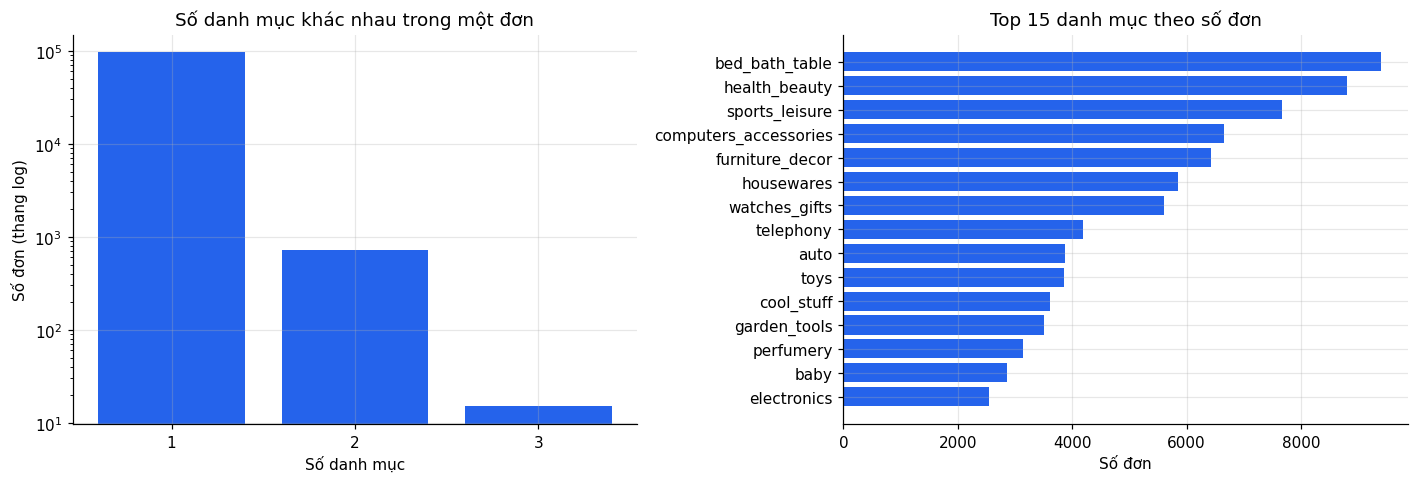

,n_orders,pct
n_categories,,
1,96098,99.250
2,711,0.734
3,15,0.015


In [15]:
basket_dist = tx_all.str.len().value_counts().sort_index().rename("n_orders").to_frame()
basket_dist.index.name = "n_categories"
basket_dist["pct"] = (basket_dist["n_orders"] / basket_dist["n_orders"].sum() * 100).round(3)
basket_dist.to_csv(OUT_TAB / "basket_size_distribution.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(basket_dist.index.astype(str), basket_dist["n_orders"], color="#2563eb")
axes[0].set_yscale("log")
axes[0].set(title="Số danh mục khác nhau trong một đơn", xlabel="Số danh mục",
            ylabel="Số đơn (thang log)")
top15 = onehot_all.sum().sort_values(ascending=False).head(15)[::-1]
axes[1].barh(top15.index, top15.values, color="#2563eb")
axes[1].set(title="Top 15 danh mục theo số đơn", xlabel="Số đơn")
fig.tight_layout()
fig.savefig(OUT_FIG / "01_basket_distribution.png")
plt.show()
basket_dist

## §4. Apriori vs FP-Growth – khảo sát minsup

- Thời gian = **trung vị** của `N_REPEATS` lần chạy, chỉ đo bước tìm tập phổ biến.
- Cột `same_itemsets` kiểm chứng hai thuật toán cho cùng tập phổ biến.
- Apriori (mlxtend, dense) cần bộ nhớ ~ số giỏ × số cặp ứng viên × 3 byte; vượt ngân sách thì bỏ qua (ghi NaN).

In [16]:
def time_algo(func, onehot, minsup, repeats=N_REPEATS):
    times, result = [], None
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = func(onehot, min_support=minsup, use_colnames=True, max_len=MAX_LEN)
        times.append(time.perf_counter() - t0)
    return float(np.median(times)), result


def make_rules(freq, n_tx, min_conf):
    if freq.empty or freq["itemsets"].str.len().max() < 2:
        return pd.DataFrame()
    kwargs = dict(metric="confidence", min_threshold=min_conf)
    if "num_itemsets" in inspect.signature(association_rules).parameters:   # mlxtend >= 0.23.2
        kwargs["num_itemsets"] = n_tx
    return association_rules(freq, **kwargs)


def apriori_mem_gb(onehot, minsup):
    n_freq = int((onehot.mean() >= minsup).sum())
    return len(onehot) * (n_freq * (n_freq - 1) // 2) * 3 / 1024 ** 3


def benchmark(onehot, scenario):
    rows = []
    for minsup in MINSUP_GRID[scenario]:
        t_fp, f_fp = time_algo(fpgrowth, onehot, minsup)
        est = apriori_mem_gb(onehot, minsup)
        if est <= APRIORI_MEM_BUDGET_GB:
            t_ap, f_ap = time_algo(apriori, onehot, minsup)
            same = set(f_ap["itemsets"]) == set(f_fp["itemsets"])
        else:
            t_ap, same = np.nan, np.nan
        gc.collect()
        rules = make_rules(f_fp, len(onehot), MIN_CONF_BENCH)
        rows.append({"scenario": scenario, "n_transactions": len(onehot), "minsup": minsup,
                     "minsup_count": int(np.ceil(minsup * len(onehot))),
                     "apriori_est_mem_gb": round(est, 3),
                     "apriori_sec": round(t_ap, 4), "fpgrowth_sec": round(t_fp, 4),
                     "speedup_fp_vs_ap": round(t_ap / t_fp, 2) if t_fp > 0 else np.nan,
                     "n_itemsets": len(f_fp),
                     "n_itemsets_len2plus": int((f_fp["itemsets"].str.len() >= 2).sum()),
                     "n_rules": len(rules),
                     f"n_rules_lift>={MIN_LIFT}": int((rules["lift"] >= MIN_LIFT).sum()) if len(rules) else 0,
                     "same_itemsets": same})
    return pd.DataFrame(rows)


bench = pd.concat([benchmark(onehot_all, "all"), benchmark(onehot_multi, "multi")],
                  ignore_index=True)
bench.to_csv(OUT_TAB / "benchmark_apriori_vs_fpgrowth.csv", index=False)
bench

,scenario,n_transactions,minsup,minsup_count,apriori_est_mem_gb,apriori_sec,fpgrowth_sec,speedup_fp_vs_ap,n_itemsets,n_itemsets_len2plus,n_rules,n_rules_lift>=1.2,same_itemsets
0,all,96824,0.0100,969,0.057,0.1800,0.4815,0.37,21,0,0,0,True
1,all,96824,0.0050,485,0.095,0.2473,0.4790,0.52,27,0,0,0,True
2,all,96824,0.0020,194,0.244,0.6443,0.4901,1.31,43,0,0,0,True
3,all,96824,0.0010,97,0.359,0.9436,0.4937,1.91,52,0,0,0,True
4,all,96824,0.0005,49,0.447,1.2014,0.7148,1.68,59,1,1,0,True
5,all,96824,0.0003,30,0.512,1.3859,0.8472,1.64,64,2,2,0,True
6,all,96824,0.0002,20,0.598,1.5429,1.3877,1.11,72,5,2,0,True
7,all,96824,0.0001,10,0.653,1.7069,3.4568,0.49,87,17,4,0,True
8,multi,726,0.1000,73,0.000,0.0023,0.0074,0.30,5,0,0,0,True
9,multi,726,0.0500,37,0.000,0.0032,0.0127,0.26,14,2,4,4,True


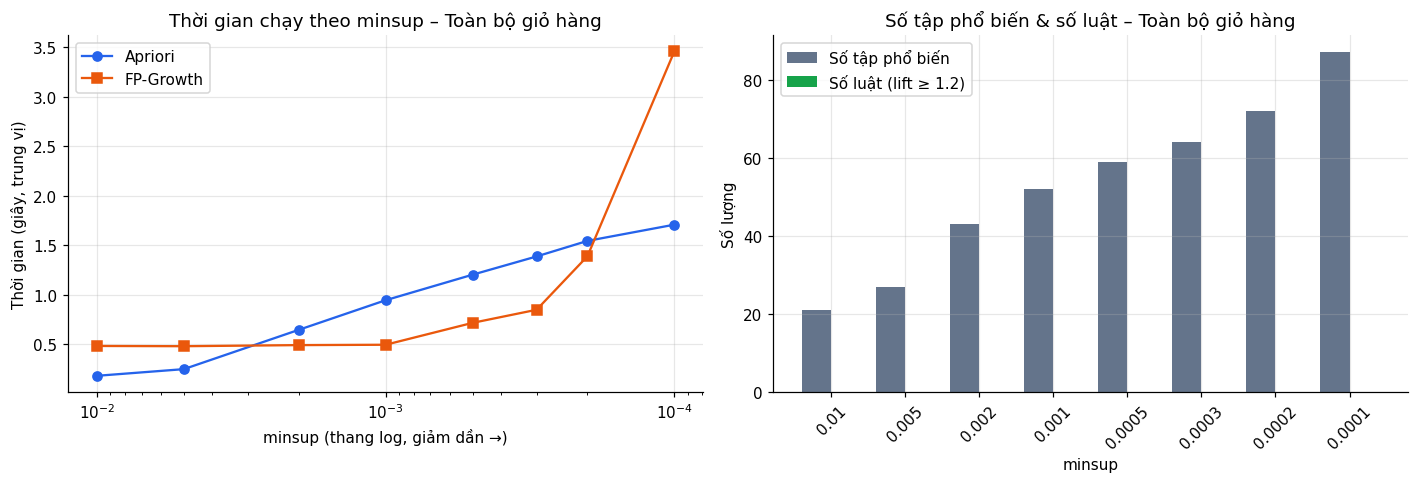

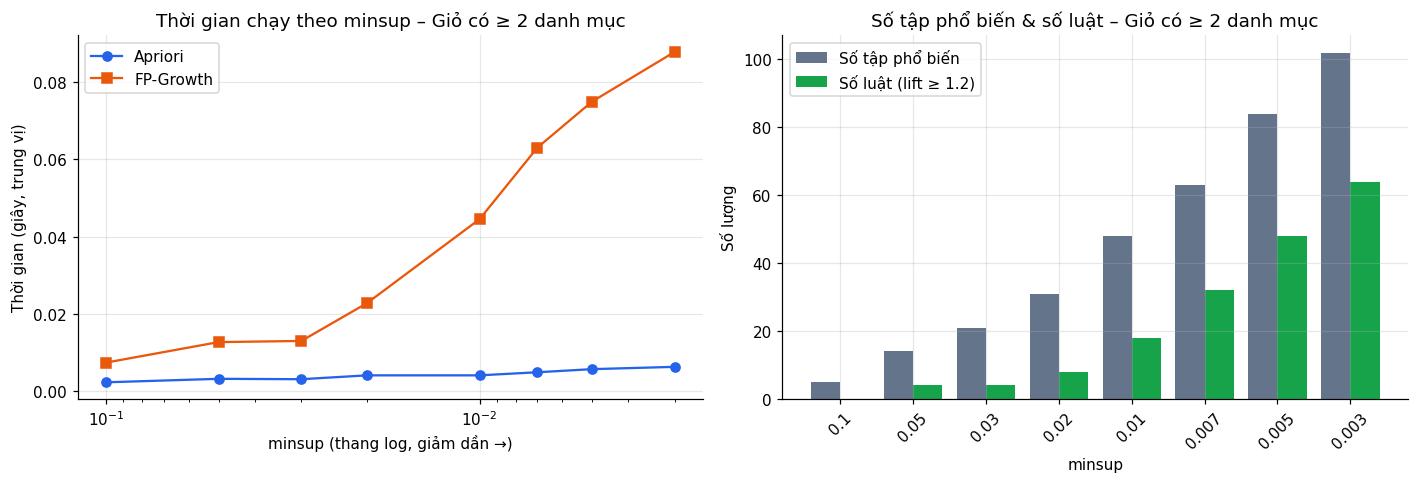

In [17]:
COLORS = {"Apriori": "#2563eb", "FP-Growth": "#ea580c"}
rule_col = f"n_rules_lift>={MIN_LIFT}"
for scenario, g in bench.groupby("scenario"):
    title = "Toàn bộ giỏ hàng" if scenario == "all" else "Giỏ có ≥ 2 danh mục"
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(g["minsup"], g["apriori_sec"], "o-", label="Apriori", color=COLORS["Apriori"])
    axes[0].plot(g["minsup"], g["fpgrowth_sec"], "s-", label="FP-Growth", color=COLORS["FP-Growth"])
    axes[0].set_xscale("log")
    axes[0].invert_xaxis()
    axes[0].set(title=f"Thời gian chạy theo minsup – {title}",
                xlabel="minsup (thang log, giảm dần →)", ylabel="Thời gian (giây, trung vị)")
    axes[0].legend()
    x = np.arange(len(g))
    axes[1].bar(x - 0.2, g["n_itemsets"], 0.4, label="Số tập phổ biến", color="#64748b")
    axes[1].bar(x + 0.2, g[rule_col], 0.4, label=f"Số luật (lift ≥ {MIN_LIFT})", color="#16a34a")
    axes[1].set_xticks(x, [f"{m:g}" for m in g["minsup"]], rotation=45)
    axes[1].set(title=f"Số tập phổ biến & số luật – {title}", xlabel="minsup", ylabel="Số lượng")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(OUT_FIG / f"02_benchmark_{scenario}.png")
    plt.show()

### 4.1. Thí nghiệm mở rộng ở mức sản phẩm (`product_id`)
Không gian item lớn hơn nhiều (hàng trăm–hàng nghìn sản phẩm) để kiểm chứng ưu thế lý thuyết của FP-Growth.
Chỉ xét đơn có ≥ 2 sản phẩm khác nhau; lọc trước sản phẩm có < 2 đơn (không ảnh hưởng kết quả theo tính chất Apriori).

In [18]:
tx_prod = build_transactions(df, "product_id")
tx_prod = tx_prod[tx_prod.str.len() >= 2]
item_count = tx_prod.explode().value_counts()
keep = set(item_count[item_count >= min(PRODUCT_MINCOUNT_GRID)].index)
onehot_prod = encode(tx_prod.apply(lambda items: [i for i in items if i in keep]))
col_count = onehot_prod.sum()
print(f"Giỏ đa sản phẩm: {len(tx_prod):,} | sản phẩm: {len(item_count):,} | giữ lại: {onehot_prod.shape[1]:,}")

rows = []
for min_count in PRODUCT_MINCOUNT_GRID:
    minsup = min_count / len(onehot_prod)
    n_items = int((col_count >= min_count).sum())
    t_fp, f_fp = time_algo(fpgrowth, onehot_prod, minsup, repeats=1)
    est = apriori_mem_gb(onehot_prod, minsup)
    if est <= APRIORI_MEM_BUDGET_GB:
        t_ap, f_ap = time_algo(apriori, onehot_prod, minsup, repeats=1)
        same, status = set(f_ap["itemsets"]) == set(f_fp["itemsets"]), "ok"
    else:
        t_ap, same, status = np.nan, np.nan, f"bỏ qua: cần ~{est:.1f} GB RAM"
    gc.collect()
    rows.append({"n_transactions": len(onehot_prod), "min_count": min_count, "minsup": round(minsup, 6),
                 "n_frequent_items": n_items, "n_candidate_pairs": n_items * (n_items - 1) // 2,
                 "apriori_est_mem_gb": round(est, 3), "apriori_sec": round(t_ap, 4),
                 "fpgrowth_sec": round(t_fp, 4), "n_itemsets": len(f_fp),
                 "same_itemsets": same, "apriori_status": status})
bench_prod = pd.DataFrame(rows)
bench_prod.to_csv(OUT_TAB / "benchmark_product_level.csv", index=False)
bench_prod

Giỏ đa sản phẩm: 3,231 | sản phẩm: 4,881 | giữ lại: 908


,n_transactions,min_count,minsup,n_frequent_items,n_candidate_pairs,apriori_est_mem_gb,apriori_sec,fpgrowth_sec,n_itemsets,same_itemsets,apriori_status
0,3231,30,0.009285,5,10,0.000,0.0083,0.1132,6,True,ok
1,3231,20,0.006190,9,36,0.000,0.0074,0.1127,11,True,ok
2,3231,15,0.004643,13,78,0.001,0.0082,0.1199,16,True,ok
3,3231,10,0.003095,24,276,0.002,0.0166,0.1285,29,True,ok
4,3231,7,0.002167,57,1596,0.014,0.0466,0.1897,66,True,ok
5,3231,5,0.001548,131,8515,0.077,0.2153,0.2985,153,True,ok
6,3231,4,0.001238,196,19110,0.173,0.3525,0.3191,226,True,ok
7,3231,3,0.000929,363,65703,0.593,1.1756,0.5699,430,True,ok
8,3231,2,0.000619,908,411778,3.717,NaN,1.4294,1124,NaN,bỏ qua: cần ~3.7 GB RAM


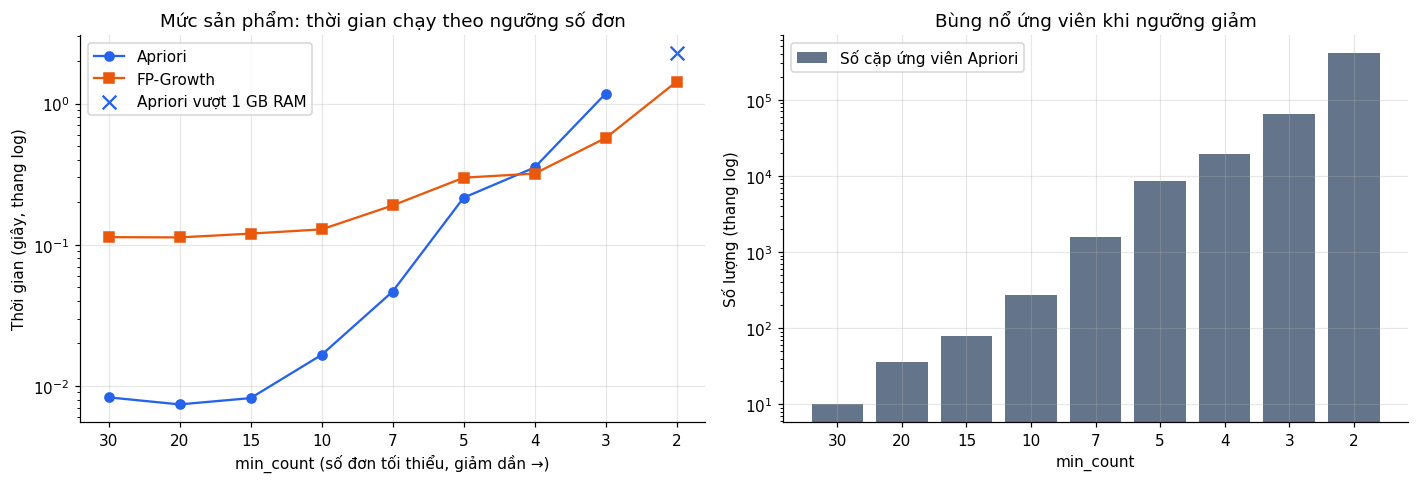

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = bench_prod["min_count"].astype(str)
ok = bench_prod["apriori_sec"].notna()
axes[0].plot(x[ok], bench_prod.loc[ok, "apriori_sec"], "o-", label="Apriori", color=COLORS["Apriori"])
axes[0].plot(x, bench_prod["fpgrowth_sec"], "s-", label="FP-Growth", color=COLORS["FP-Growth"])
if (~ok).any():
    y_mark = np.nanmax(bench_prod[["apriori_sec", "fpgrowth_sec"]].values) * 1.6
    axes[0].scatter(x[~ok], [y_mark] * (~ok).sum(), marker="x", s=80, color=COLORS["Apriori"],
                    label=f"Apriori vượt {APRIORI_MEM_BUDGET_GB:g} GB RAM")
axes[0].set_yscale("log")
axes[0].set(title="Mức sản phẩm: thời gian chạy theo ngưỡng số đơn",
            xlabel="min_count (số đơn tối thiểu, giảm dần →)", ylabel="Thời gian (giây, thang log)")
axes[0].legend()
axes[1].bar(x, bench_prod["n_candidate_pairs"], color="#64748b", label="Số cặp ứng viên Apriori")
axes[1].set_yscale("log")
axes[1].set(title="Bùng nổ ứng viên khi ngưỡng giảm", xlabel="min_count", ylabel="Số lượng (thang log)")
axes[1].legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT_FIG / "06_benchmark_product_level.png")
plt.show()

## §5. Đánh giá và sinh luật

### 5.1. Lift của các cặp danh mục: ALL vs MULTI
Vì > 99% đơn chỉ có một danh mục, lift tính trên ALL bị kéo xuống < 1 với gần như mọi cặp
(đo việc khách có mua nhiều danh mục hay không, chứ không đo danh mục nào đi với danh mục nào).
Bảng dưới đây là căn cứ để sinh luật cuối cùng trên kịch bản **MULTI**.

In [20]:
def pair_lift_comparison(onehot_all, onehot_multi, min_pair_count=MIN_PAIR_COUNT):
    m = onehot_multi.astype(np.int32)
    co = m.T @ m                                     # số đơn chứa đồng thời 2 danh mục
    n_all, n_multi = len(onehot_all), len(onehot_multi)
    cnt_all, cnt_multi = onehot_all.sum(), onehot_multi.sum()
    cats, rows = list(co.columns), []
    for i, a in enumerate(cats):
        for b in cats[i + 1:]:
            n = int(co.at[a, b])
            if n >= min_pair_count:
                rows.append({"cat_a": a, "cat_b": b, "pair_count": n,
                             "lift_all": n * n_all / (cnt_all[a] * cnt_all[b]),
                             "lift_multi": n * n_multi / (cnt_multi[a] * cnt_multi[b])})
    return pd.DataFrame(rows).sort_values("pair_count", ascending=False).reset_index(drop=True)


pairs = pair_lift_comparison(onehot_all, onehot_multi)
pairs.to_csv(OUT_TAB / "pair_lift_all_vs_multi.csv", index=False)
print(f"{len(pairs)} cặp có ≥ {MIN_PAIR_COUNT} đơn chung | lift ALL < 1: {(pairs['lift_all'] < 1).mean():.0%} "
      f"| lift MULTI ≥ {MIN_LIFT}: {(pairs['lift_multi'] >= MIN_LIFT).sum()}")
pairs.head(15).round(3)

36 cặp có ≥ 5 đơn chung | lift ALL < 1: 97% | lift MULTI ≥ 1.2: 23


,cat_a,cat_b,pair_count,lift_all,lift_multi
0,bed_bath_table,furniture_decor,70,0.112,1.264
1,bed_bath_table,home_confort,43,1.116,3.153
2,furniture_decor,housewares,24,0.062,0.841
3,baby,cool_stuff,20,0.187,2.366
4,bed_bath_table,housewares,20,0.035,0.719
5,baby,toys,19,0.166,2.966
6,furniture_decor,garden_tools,17,0.073,0.833
7,baby,bed_bath_table,17,0.061,0.670
8,health_beauty,sports_leisure,14,0.020,2.199
9,furniture_decor,home_construction,13,0.401,1.788


### 5.2. Sinh luật trên kịch bản MULTI, lọc và chọn Top 20

In [21]:
def to_text(itemset):
    return ", ".join(sorted(itemset))


freq = fpgrowth(onehot_multi, min_support=FINAL_MINSUP, use_colnames=True, max_len=MAX_LEN)
rules = make_rules(freq, len(onehot_multi), FINAL_MIN_CONF)
rules["pair_count"] = (rules["support"] * len(onehot_multi)).round().astype(int)
rules["antecedents_str"] = rules["antecedents"].apply(to_text)
rules["consequents_str"] = rules["consequents"].apply(to_text)
rules["rule"] = rules["antecedents_str"] + "  →  " + rules["consequents_str"]
rules = rules[["rule", "antecedents_str", "consequents_str", "antecedent support",
               "consequent support", "support", "pair_count", "confidence", "lift",
               "leverage", "conviction"]].sort_values("lift", ascending=False).reset_index(drop=True)

# Lọc: lift rõ rệt > 1 và đủ số đơn; khử trùng chiều A→B / B→A (giữ confidence cao hơn)
valuable = rules[(rules["lift"] >= MIN_LIFT) & (rules["pair_count"] >= MIN_PAIR_COUNT)].copy()
valuable["itemset_key"] = [to_text(set(a.split(", ")) | set(c.split(", ")))
                           for a, c in zip(valuable["antecedents_str"], valuable["consequents_str"])]
top = (valuable.sort_values("confidence", ascending=False).drop_duplicates("itemset_key")
       .sort_values(["lift", "confidence"], ascending=False).head(TOP_K)
       .drop(columns="itemset_key").reset_index(drop=True))
top.index = top.index + 1

print(f"Tập phổ biến: {len(freq)} | luật (conf ≥ {FINAL_MIN_CONF}): {len(rules)} | "
      f"luật có giá trị: {len(valuable)} | Top: {len(top)}")
top[["rule", "support", "pair_count", "confidence", "lift"]].round(4)

Tập phổ biến: 84 | luật (conf ≥ 0.05): 76 | luật có giá trị: 43 | Top: 20


,rule,support,pair_count,confidence,lift
1,audio → watches_gifts,0.0083,6,1.0000,18.1500
2,luggage_accessories → stationery,0.0069,5,0.3333,7.8065
3,perfumery → health_beauty,0.0152,11,0.4400,4.6296
4,telephony → computers_accessories,0.0083,6,0.2222,3.1634
5,home_confort → bed_bath_table,0.0592,43,0.8600,3.1533
6,electronics → computers_accessories,0.0069,5,0.2174,3.0946
7,art → furniture_decor,0.0069,5,0.8333,2.9803
8,toys → baby,0.0262,19,0.3800,2.9665
9,construction_tools_construction → garden_tools,0.0069,5,0.2941,2.9251
10,stationery → toys,0.0083,6,0.1935,2.8103


In [22]:
freq.assign(itemsets=freq["itemsets"].apply(to_text), length=freq["itemsets"].str.len()) \
    .sort_values("support", ascending=False).to_csv(OUT_TAB / "frequent_itemsets.csv", index=False)
rules.to_csv(OUT_TAB / "all_rules.csv", index=False)
top.to_csv(OUT_TAB / f"top{TOP_K}_rules.csv", index_label="rank")
rules[rules["lift"] > 1].to_csv(MODEL_DIR / "rules.csv", index=False)   # dùng cho app Streamlit
print("Đã lưu frequent_itemsets.csv, all_rules.csv, top20_rules.csv, models/rules.csv")

Đã lưu frequent_itemsets.csv, all_rules.csv, top20_rules.csv, models/rules.csv


### 5.3. Biểu đồ đánh giá luật

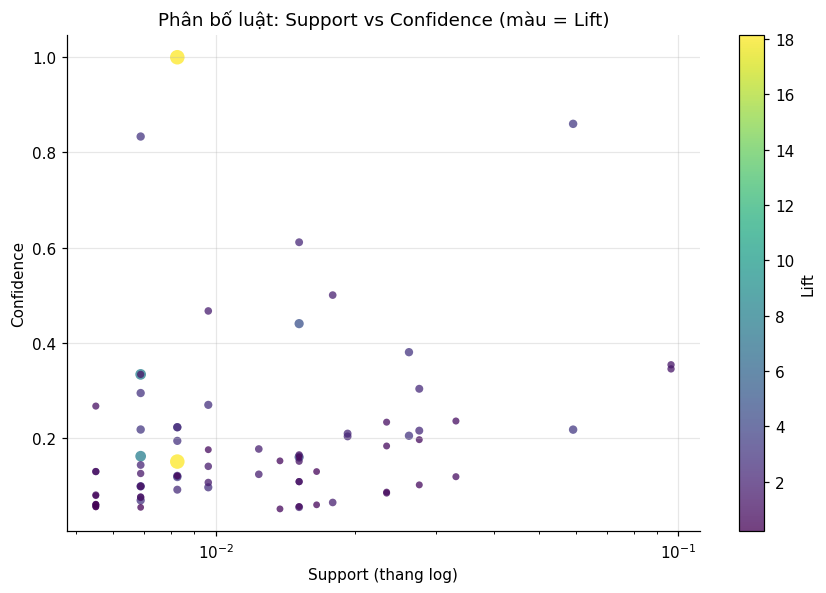

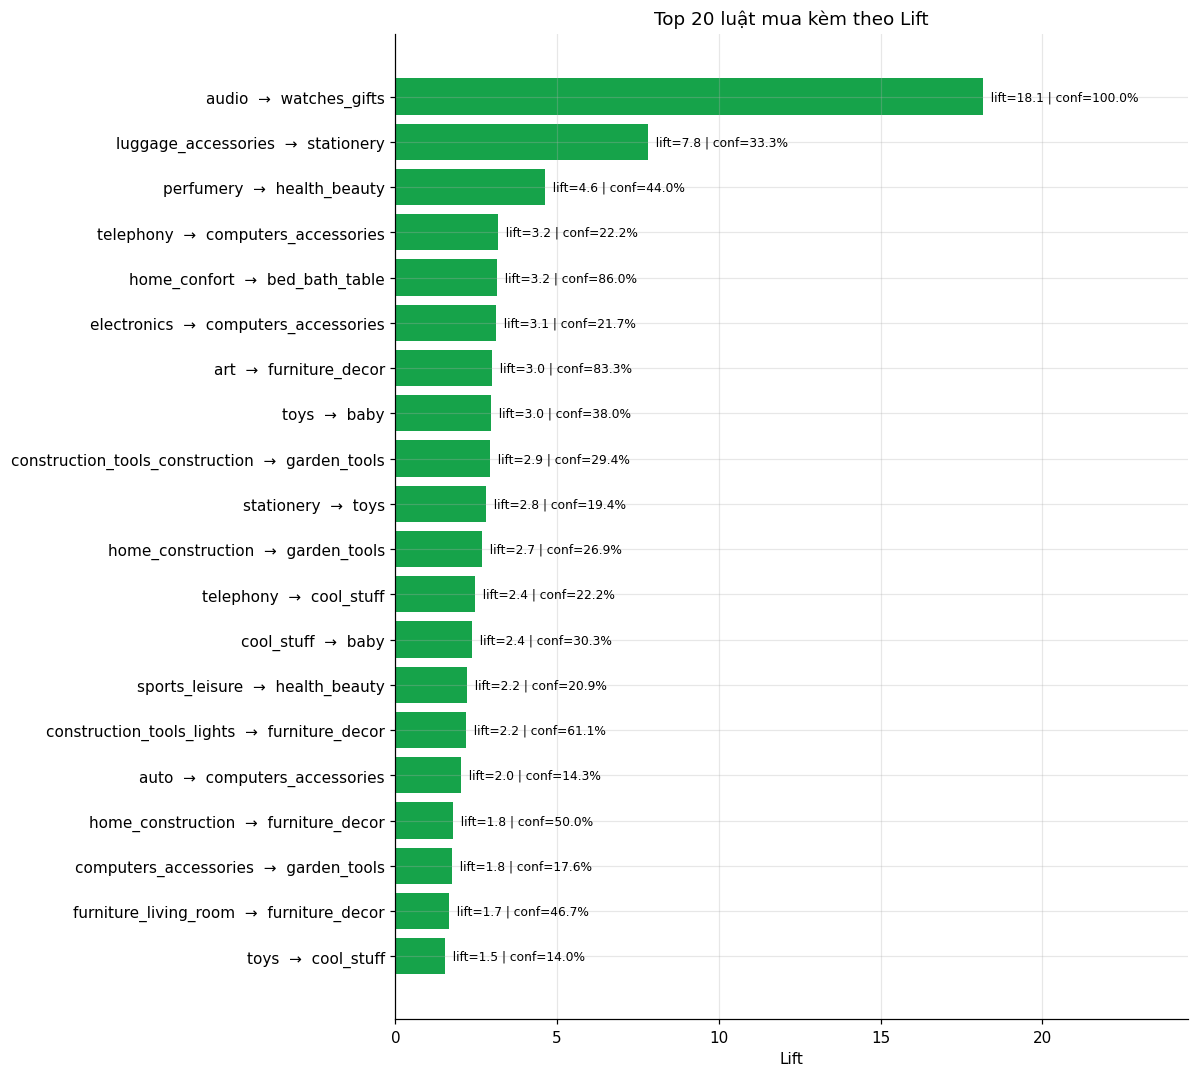

In [23]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis",
                s=18 + 4 * np.clip(rules["lift"], 0, 20), alpha=0.75, edgecolors="none")
ax.set_xscale("log")
ax.set(title="Phân bố luật: Support vs Confidence (màu = Lift)",
       xlabel="Support (thang log)", ylabel="Confidence")
fig.colorbar(sc, ax=ax, label="Lift")
fig.tight_layout()
fig.savefig(OUT_FIG / "03_rules_scatter.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 0.42 * len(top) + 1.5))
t = top.iloc[::-1]
ax.barh(t["rule"], t["lift"], color="#16a34a")
for y, (lift, conf) in enumerate(zip(t["lift"], t["confidence"])):
    ax.text(lift, y, f"  lift={lift:.1f} | conf={conf:.1%}", va="center", fontsize=8)
ax.set(title=f"Top {len(top)} luật mua kèm theo Lift", xlabel="Lift")
ax.set_xlim(0, t["lift"].max() * 1.35)
fig.tight_layout()
fig.savefig(OUT_FIG / "04_top_rules_lift.png")
plt.show()

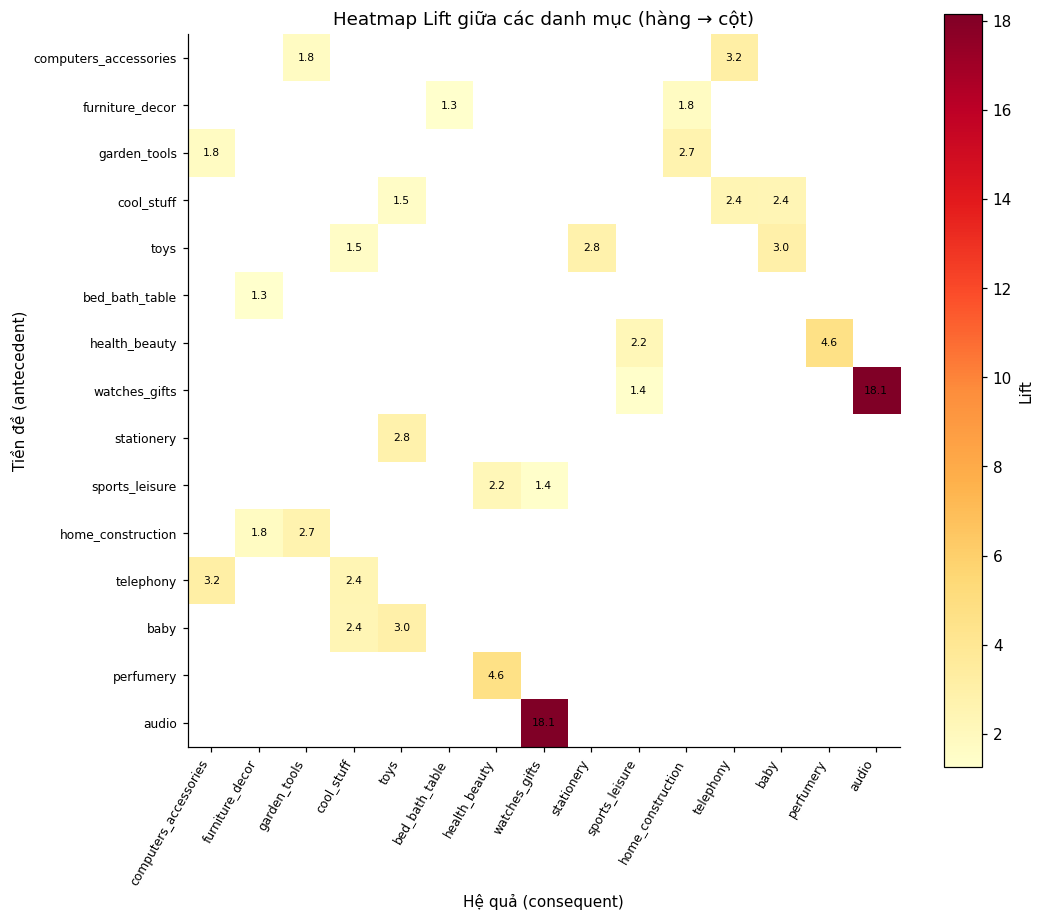

In [24]:
pair_rules = valuable[(~valuable["antecedents_str"].str.contains(","))
                      & (~valuable["consequents_str"].str.contains(","))]
cats = pd.concat([pair_rules["antecedents_str"], pair_rules["consequents_str"]]).value_counts().head(15).index
mat = pair_rules.pivot_table(index="antecedents_str", columns="consequents_str",
                             values="lift").reindex(index=cats, columns=cats)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(mat.values, cmap="YlOrRd")
ax.set_xticks(range(len(cats)), cats, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cats)), cats, fontsize=8)
ax.grid(False)
for i in range(len(cats)):
    for j in range(len(cats)):
        if not np.isnan(mat.values[i, j]):
            ax.text(j, i, f"{mat.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set(title="Heatmap Lift giữa các danh mục (hàng → cột)",
       xlabel="Hệ quả (consequent)", ylabel="Tiền đề (antecedent)")
fig.colorbar(im, ax=ax, label="Lift")
fig.tight_layout()
fig.savefig(OUT_FIG / "05_lift_heatmap.png")
plt.show()

## §6. Tổng hợp số liệu chính

Các con số dưới đây được ghi vào `outputs/tables/phase2_summary.json` và là nguồn số liệu duy nhất
để đối chiếu với báo cáo Word và video. **Lưu ý:** thời gian chạy phụ thuộc máy và lần chạy,
nên báo cáo cần dùng đúng số của lần chạy notebook dùng để nộp.

In [25]:
phase2_summary = {
    "n_transactions": len(onehot_all), "n_categories": onehot_all.shape[1],
    "density": float(onehot_all.values.mean()), "n_multi": len(onehot_multi),
    "n_rules_final": len(rules), "n_rules_valuable": len(valuable), "n_top": len(top),
    "environment": {"python": platform.python_version(), "pandas": pd.__version__,
                    "numpy": np.__version__, "mlxtend": mlxtend.__version__,
                    "os": f"{platform.system()} {platform.release()}",
                    "processor": platform.processor()},
}
(OUT_TAB / "phase2_summary.json").write_text(json.dumps(phase2_summary, indent=2, ensure_ascii=False),
                                            encoding="utf-8")
pd.Series({k: v for k, v in phase2_summary.items() if k != "environment"})

n_transactions      96824.000000
n_categories           73.000000
density                 0.013803
n_multi               726.000000
n_rules_final          76.000000
n_rules_valuable       43.000000
n_top                  20.000000
dtype: float64